# **Прикладные задачи МО на графах. 03.12.2025**

Библиотека для работы с графовыми нейронными сетями  
[PyG (PyTorch Geometric)](https://github.com/rusty1s/pytorch_geometric).
PyTorch Geometric  - это расширение к [PyTorch](https://pytorch.org/).

In [2]:
# Install torch geometric
import os
import torch

In [3]:
!pip install torch==2.4.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.2/797.2 MB 772.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 71.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 57.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.6/823.6 kB 30.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 MB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.5/56.5 MB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.2/124.2 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 196.0/196.0 MB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 176.2/176.2 MB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.1/99.1 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [4]:
torch_version = str(torch.__version__)
scatter_src = f"https://pytorch-geometric.com/whl/torch-{torch_version}.html"
sparse_src = f"https://pytorch-geometric.com/whl/torch-{torch_version}.html"
!pip install torch-scatter -f $scatter_src
!pip install torch-sparse -f $sparse_src
!pip install torch-geometric
!pip install -q git+https://github.com/snap-stanford/deepsnap.git

Looking in links: https://pytorch-geometric.com/whl/torch-2.9.0+cpu.html
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.0/108.0 kB 4.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for torch-scatter: filename=torch_scatter-2.1.2-cp312-cp312-linux_x86_64.whl size=539311 sha256=7e3981128682fba00f361921ecc3a049e3fdcdd127a28f529e4423d3e09142a3
  Stored in directory: /root/.cache/pip/wheels/84/20/50/44800723f57cd798630e77b3ec83bc80bd26a1e3dc3a672ef5
Successfully built torch-scatter
Looking in links: https://pytorch-geometric.com/whl/torch-2.9.0+cpu.html
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 210.0/210.0 kB 6.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for torch-sparse: filename=torch_sparse-0.6.18-cp312-cp312-linux_x86_64.whl size=1130710 sha256=9c9db2629bed8058eebc5174df5614cb8a7675d90b00b19d1dd882773fae84f9
  Stored in directory: /root/.cache/pip/wheels/71/fa/21/bd1d78ce1629aec4ecc924a63b82f6949dda484b6321eac6f2
Successfu

In [5]:
import torch_geometric
torch_geometric.__version__

/usr/local/lib/python3.12/dist-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'torch-scatter'. Disabling its usage. Stacktrace: Could not load this library: /usr/local/lib/python3.12/dist-packages/torch_scatter/_version_cpu.so
  import torch_geometric.typing
/usr/local/lib/python3.12/dist-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'torch-sparse'. Disabling its usage. Stacktrace: Could not load this library: /usr/local/lib/python3.12/dist-packages/torch_sparse/_version_cpu.so
  import torch_geometric.typing


AttributeError: type object 'GuardSource' has no attribute 'LOCAL_NN_MODULE'

In [ ]:
import torch.nn.functional as F
from torch_geometric.nn import SAGEConv
from torch_geometric.loader import NeighborLoader
from torch_geometric.utils import to_networkx

In [ ]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# GraphSAGE (SAmple and aggreGAte)

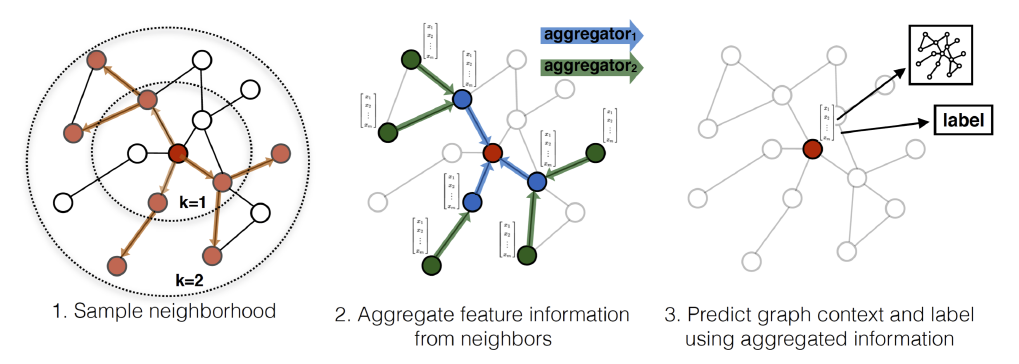

Два основных компонента GraphSAGE


*   Подвыборка соседей (neighbor sampling)
*   Агрегирования информации (aggration)


## Neighbor sampling

Batching - деление датасета на небольшие группы (batches).



*   **Batch gradient descent**: Веса и ошибки обновляются после обработки всего датасета (каждой эпохи).
* **Stochastic gradient descent**: Веса обновляются для каждого объекта выборки.
* **Mini-batch gradient descent**: Веса и ошибки (biases) обновляются для каждой группы (mini-batch) из $n$ объектов из выборки.

GNN вычисляют эмбеддинги узла по его соседям (1 hop), соседям соседей (2 hop) и так далее. Для каждого узла формируется свой граф вычислений (computation graph) и остальные узлы графа не участвуют в вычислениях.

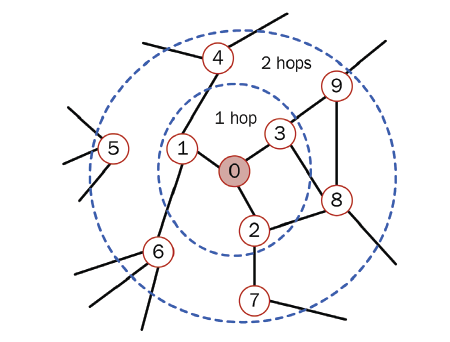
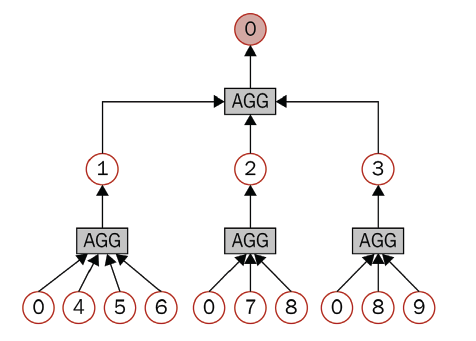

*   Граф вычислений растет с ростом числа слоев.
*   Хабы (узлы большой степени) порождают огромные вычислительные графы.

Подход GraphSAGE предлагает включать в граф вычислений только заданное число узлов в каждой окрестности. Например, выбирать только (не более) 3-х соседей узла (из 1 hop) и не более 5 соседей соседей (из 2 hop).

Граф вычислений при выборе только 2х узлов из 1-hop и 2х узлов из 2-hop.

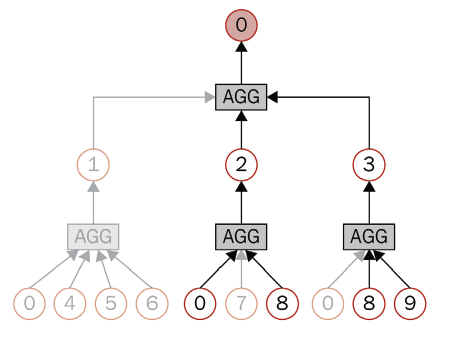

Один из вариант агрегирования информации по соседям это осреднение (mean aggregator):
$$ h_i' = \sigma(W\cdot mean_{j\in N[i]}(h_j)).$$

В PyG's реализован вариант с двумя матрицами весов - одна для узла, вторая - для соседей узла.

$$ h_i' = \sigma(W_1 h_i + W_2\cdot mean_{j\in N(i)}(h_j)).$$

PubMed dataset: 19717 узлов, 88649 рёбер.

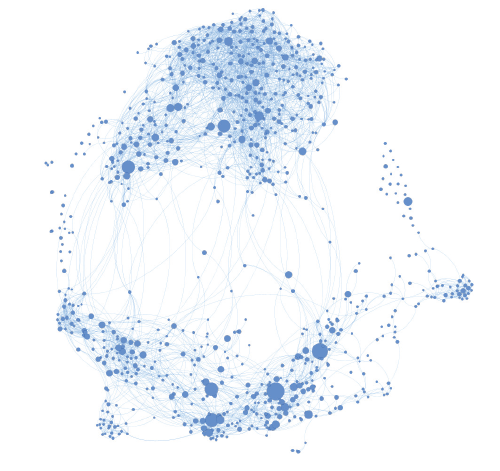

In [ ]:
from torch_geometric.datasets import Planetoid

dataset = Planetoid(root='.', name="Pubmed")
data = dataset[0]

Processing...
Done!


In [ ]:
# Сведения о датасете
print(f'Dataset: {dataset}')
print('-------------------')
print(f'Number of graphs: {len(dataset)}')
print(f'Number of nodes: {data.x.shape[0]}')
print(f'Number of features: {dataset.num_features}')
print(f'Number of classes: {dataset.num_classes}')

# Сведения о графе
print(f'\nGraph:')
print('------')
print(f'Training nodes: {sum(data.train_mask).item()}')
print(f'Evaluation nodes: {sum(data.val_mask).item()}')
print(f'Test nodes: {sum(data.test_mask).item()}')
print(f'Edges are directed: {data.is_directed()}')
print(f'Graph has isolated nodes: {data.has_isolated_nodes()}')
print(f'Graph has loops: {data.has_self_loops()}')

Dataset: Pubmed()
-------------------
Number of graphs: 1
Number of nodes: 19717
Number of features: 500
Number of classes: 3

Graph:
------
Training nodes: 60
Evaluation nodes: 500
Test nodes: 1000
Edges are directed: False
Graph has isolated nodes: False
Graph has loops: False


Neighbor sampling: 10 соседей (1-hop) и 10 соседей соседей (2-hop).

In [ ]:
data

Data(x=[19717, 500], edge_index=[2, 88648], y=[19717], train_mask=[19717], val_mask=[19717], test_mask=[19717])

In [ ]:
from torch_geometric.loader import NeighborLoader
from torch_geometric.utils import to_networkx

# Делим узлы на группы (batches)
train_loader = NeighborLoader(
    data,
    num_neighbors=[10, 10],
    batch_size=16,
    input_nodes=data.train_mask,
)

/usr/local/lib/python3.12/dist-packages/torch_geometric/loader/neighbor_loader.py:229: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


In [ ]:
# Нумерация для подгрупп
for i, subgraph in enumerate(train_loader):
    print(f'Subgraph {i}: {subgraph}')

Subgraph 0: Data(x=[505, 500], edge_index=[2, 613], y=[505], train_mask=[505], val_mask=[505], test_mask=[505], n_id=[505], e_id=[613], input_id=[16], batch_size=16)
Subgraph 1: Data(x=[287, 500], edge_index=[2, 368], y=[287], train_mask=[287], val_mask=[287], test_mask=[287], n_id=[287], e_id=[368], input_id=[16], batch_size=16)
Subgraph 2: Data(x=[340, 500], edge_index=[2, 415], y=[340], train_mask=[340], val_mask=[340], test_mask=[340], n_id=[340], e_id=[415], input_id=[16], batch_size=16)
Subgraph 3: Data(x=[236, 500], edge_index=[2, 293], y=[236], train_mask=[236], val_mask=[236], test_mask=[236], n_id=[236], e_id=[293], input_id=[12], batch_size=12)


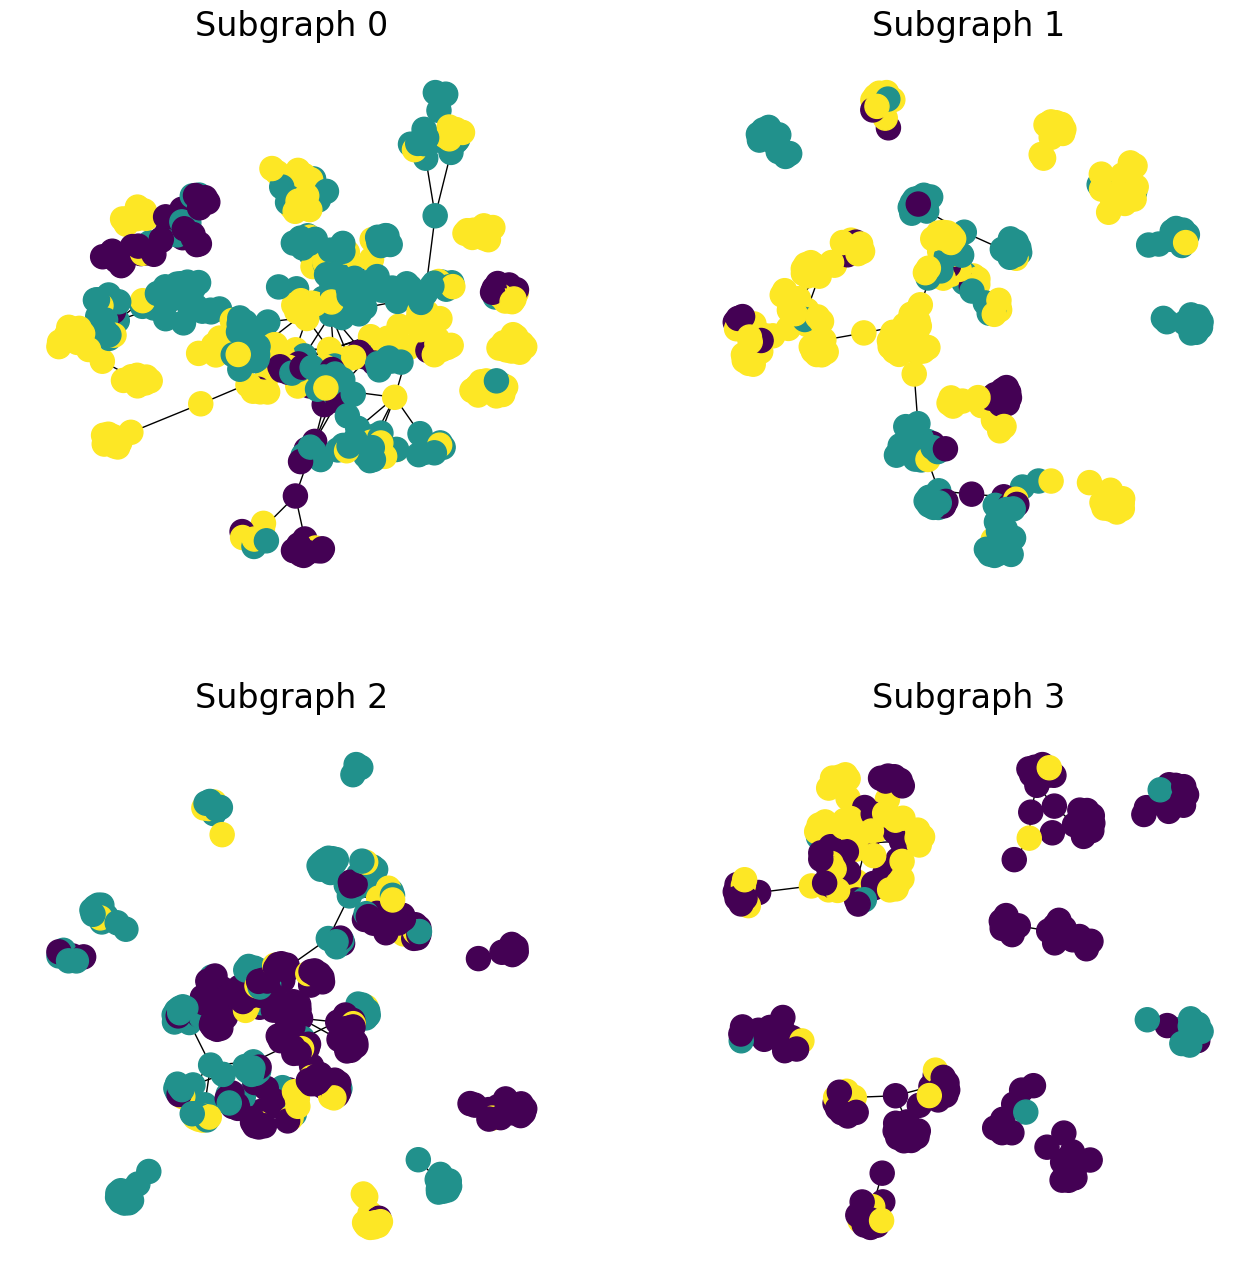

In [ ]:
# Plot each subgraph
fig = plt.figure(figsize=(16,16))
for idx, (subdata, pos) in enumerate(zip(train_loader, [221, 222, 223, 224])):
    G = to_networkx(subdata, to_undirected=True)
    ax = fig.add_subplot(pos)
    ax.set_title(f'Subgraph {idx}', fontsize=24)
    plt.axis('off')
    nx.draw_networkx(G,
                    pos=nx.spring_layout(G, seed=0),
                    with_labels=False,
                    node_color=subdata.y,
                    )
plt.show()

Метрика accuracy доля правильных ответов алгоритма:

$ACCURACY = \cfrac{TP + TN}{TP+TN+FP+FN}$.

сеть из 2-х слоев:


*   SAGEConv с осреднением информации от соседей)
*   Функция активации ReLU
* Dropout слой

In [ ]:
def accuracy(pred_y, y):
    return ((pred_y == y).sum() / len(y)).item()

In [ ]:
class GraphSAGE(torch.nn.Module):
    """GraphSAGE"""
    def __init__(self, dim_in, dim_h, dim_out):
        super().__init__()
        self.sage1 = SAGEConv(dim_in, dim_h)
        self.sage2 = SAGEConv(dim_h, dim_out)

    def forward(self, x, edge_index):
        h = self.sage1(x, edge_index)
        h = torch.relu(h)
        h = F.dropout(h, p=0.3, training=self.training)
        h = self.sage2(h, edge_index)
        return F.log_softmax(h, dim=1)

    def fit(self, data, epochs):
        criterion = torch.nn.CrossEntropyLoss()
        optimizer = torch.optim.Adam(self.parameters(), lr=0.01)

        self.train()
        for epoch in range(epochs+1):
            total_loss, val_loss, acc, val_acc = 0, 0, 0, 0

            # Обучение в группах (batches)
            for batch in train_loader:
                optimizer.zero_grad()
                out = self(batch.x, batch.edge_index)
                loss = criterion(out[batch.train_mask], batch.y[batch.train_mask])
                total_loss += loss.item()
                acc += accuracy(out[batch.train_mask].argmax(dim=1), batch.y[batch.train_mask])
                loss.backward()
                optimizer.step()

                # Валидация
                val_loss += criterion(out[batch.val_mask], batch.y[batch.val_mask])
                val_acc += accuracy(out[batch.val_mask].argmax(dim=1), batch.y[batch.val_mask])

            # Вывод метрик каждые 20 эпох
            if epoch % 10 == 0:
                print(f'Epoch {epoch:>3} | Train Loss: {loss/len(train_loader):.3f} | Train Acc: {acc/len(train_loader)*100:>6.2f}% | Val Loss: {val_loss/len(train_loader):.2f} | Val Acc: {val_acc/len(train_loader)*100:.2f}%')

    @torch.no_grad()
    def test(self, data):
        self.eval()
        out = self(data.x, data.edge_index)
        acc = accuracy(out.argmax(dim=1)[data.test_mask], data.y[data.test_mask])
        return acc

In [ ]:
# Создаем GraphSAGE (скрытый слой размерности 64)
graphsage = GraphSAGE(dataset.num_features, 64, dataset.num_classes)
print(graphsage)

# Обучение
graphsage.fit(train_loader, 200)

# Тестирование
acc = graphsage.test(data)
print(f'GraphSAGE test accuracy: {acc*100:.2f}%')

# Задание (?)

Работа по статье [Inductive Representation Learning on Large Graph](https://arxiv.org/pdf/1706.02216)

Предсказание принадлежности узла сообществу для датасета
[Reddit](https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.datasets.Reddit.html#torch_geometric.datasets.Reddit) c помощью GraphSAGE.

* Число слоев - 2
* Число узлов для подвыборок (sampling): $S_1 = 25$ для первого слоя; $S_2 = 10$ для второго слоя.

In [ ]:
from torch_geometric.datasets import Reddit

dataset = Reddit(root="data/Reddit")
data = dataset[0]
print(data)


In [8]:
# Сведения о датасете
print(f'Dataset: {dataset}')
print('-------------------')
print(f'Number of graphs: {len(dataset)}')
print(f'Number of nodes: {data.x.shape[0]}')
print(f'Number of features: {dataset.num_features}')
print(f'Number of classes: {dataset.num_classes}')

# Сведения о графе
print(f'\nGraph:')
print('------')
print(f'Training nodes: {sum(data.train_mask).item()}')
print(f'Evaluation nodes: {sum(data.val_mask).item()}')
print(f'Test nodes: {sum(data.test_mask).item()}')
print(f'Edges are directed: {data.is_directed()}')
print(f'Graph has isolated nodes: {data.has_isolated_nodes()}')
print(f'Graph has loops: {data.has_self_loops()}')

Dataset: Reddit()
-------------------
Number of graphs: 1
Number of nodes: 232965
Number of features: 602
Number of classes: 41

Graph:
------
Training nodes: 153431
Evaluation nodes: 23831
Test nodes: 55703
Edges are directed: False
Graph has isolated nodes: False
Graph has loops: False


In [ ]:

# Создаём загрузчик батчей с семплированием соседей
train_loader = NeighborLoader(
    data,
    input_nodes=data.train_mask,
    num_neighbors=[25, 10],   # S1=25, S2=10
    batch_size=512,
    shuffle=True
)

# Нумерация для подгрупп
for i, subgraph in enumerate(train_loader):
    print(f'Subgraph {i}: {subgraph}')

KeyboardInterrupt: 

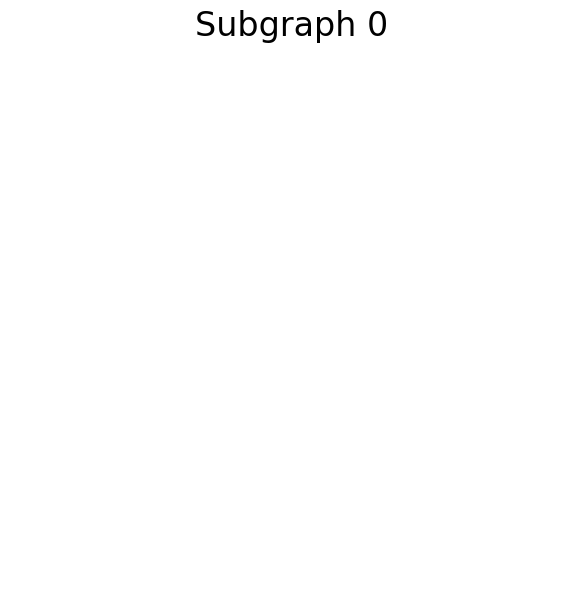

In [12]:
# # Plot each subgraph
# fig = plt.figure(figsize=(16,16))
# for idx, (subdata, pos) in enumerate(zip(train_loader, [221, 222, 223, 224])):
#     G = to_networkx(subdata, to_undirected=True)
#     ax = fig.add_subplot(pos)
#     ax.set_title(f'Subgraph {idx}', fontsize=24)
#     plt.axis('off')
#     nx.draw_networkx(G,
#                     pos=nx.spring_layout(G, seed=0),
#                     with_labels=False,
#                     node_color=subdata.y,
#                     )
# plt.show()

In [ ]:

# # Создаём загрузчик батчей с семплированием соседей
# train_loader = NeighborLoader(
#     data,
#     input_nodes=data.train_mask,
#     num_neighbors=[25, 10],   # S1=25, S2=10
#     batch_size=512,
#     shuffle=True
# )

# Создаём модель
model = GraphSAGE(dataset.num_features, 256, dataset.num_classes)

# Обучение
model.fit(data, epochs=50)

# Тестирование
acc = model.test(data)
print(f"Test Accuracy: {acc*100:.2f}%")

Epoch   0 | Train Loss: 0.001 | Train Acc:  83.32% | Val Loss: 1.01 | Val Acc: 74.46%
Epoch  10 | Train Loss: 0.001 | Train Acc:  93.23% | Val Loss: 2.11 | Val Acc: 72.91%
Epoch  20 | Train Loss: 0.001 | Train Acc:  93.80% | Val Loss: 2.73 | Val Acc: 71.97%


In [ ]:

# # Создаём загрузчик батчей с семплированием соседей
# train_loader = NeighborLoader(
#     data,
#     input_nodes=data.train_mask,
#     num_neighbors=[25, 10],   # S1=25, S2=10
#     batch_size=1024,
#     shuffle=True
# )

# Создаём модель
model = GraphSAGE(dataset.num_features, 128, dataset.num_classes)

# Обучение
model.fit(data, epochs=100)

# Тестирование
acc = model.test(data)
print(f"Test Accuracy: {acc*100:.2f}%")